# Parameter identification with data fitting
After conducting the experiment, we compare the recorded data with the calculated behavior of the mathematical model of the DC motor.

| column | meaning | unit |
|---|---|---|
| 0 | phase |
| 1 | motor power setpoint | % |
| 2 | left wheel encoder (E4) | deg |
| 3 | right wheel encoder (E3) | deg |
| 4 | time since start of this power level | ms |
| 5 | battery voltage | V |

Because the battery voltage is logged, we can use the **actual voltage** applied to the motor, $U = \frac{power}{100}\,U_{bat}$, instead of a guessed constant.

In [30]:
try:
    from google.colab import files    # file work module
    uploaded = files.upload()         # upload file context window
except ImportError:
    pass

Using the *loadtxt* function from the *numpy* module we read all six columns. The file holds many experiments one after another, so we split it into separate runs wherever the power setpoint changes, and convert the readings to SI units.

In [31]:
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization
from scipy import optimize          # data fitting
from scipy.integrate import odeint  # ordinary differential equation solver

def load_runs(path):
    data = np.loadtxt(path)                                          # columns: phase, power, encL, encR, time_ms, battery
    phase_all, power_all, encL_all, encR_all, time_all, bat_all = data.T
    runs = []
    for p in np.unique(power_all):
        m = (power_all == p) & (phase_all == 1)                      # power-on lines of this level
        if not m.any():                                              # no power-on lines (power 0 in the floor run)
            continue
        runs.append({
            'power': p,                                              # setpoint, %
            'time':  time_all[m] / 1000,                             # SI conversion, s
            'L':     np.deg2rad(encL_all[m]),                        # SI conversion, rad
            'R':     np.deg2rad(encR_all[m]),                        # SI conversion, rad
            'U':     p / 100 * bat_all[m].mean(),                    # applied voltage, V
        })
    return runs, bat_all

FILES = {'run1':  'steps_data.txt',                                  # wheels lifted, run 1
         'run2':  'steps_data_2.txt',                                # wheels lifted, run 2 (repeatability)
         'floor': 'steps_data_load.txt'}                             # on the floor, ±50 % only (load)
all_runs, all_bat = {}, {}
for name, path in FILES.items():
    all_runs[name], all_bat[name] = load_runs(path)
    r = all_runs[name]
    print(f'{name}: {len(r)} runs, power {r[0]["power"]:.0f} .. {r[-1]["power"]:.0f} %, '
          f'battery {all_bat[name].min():.2f} .. {all_bat[name].max():.2f} V')

runs, bat_all = all_runs['run1'], all_bat['run1']                    # the cells below analyse run 1


run1: 21 runs, power -100 .. 100 %, battery 11.64 .. 11.67 V
run2: 21 runs, power -100 .. 100 %, battery 11.29 .. 11.33 V
floor: 2 runs, power -50 .. 50 %, battery 11.29 .. 11.30 V


Next, we define the motor rotation angle function to find optimal values of the steady-state speed $\omega_{ss}$ and $T_m$:
$$\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right), \qquad \omega_{ss} = \frac{U}{k_e}$$
Having real measurements of rotation angle versus time, we use *optimize.curve_fit*. The initial guess for the speed is taken from the data itself, so it works for any power level and direction.

## Derivation of $\theta(t)$

**From the motor equations to the first-order model.**

Electrical: $L\dfrac{di}{dt} + Ri + k_e\omega = U$

Mechanical: $J\dfrac{d\omega}{dt} = k_m i$

We assume $L$ is negligible, so

$$
0 + Ri + k_e\omega = U
\quad\Rightarrow\quad
i = \frac{U - k_e\omega}{R}
$$

Substituting into the mechanical equation:

$$
J\frac{d\omega}{dt} = \frac{k_m(U - k_e\omega)}{R}
\quad\Rightarrow\quad
JR\frac{d\omega}{dt} = k_mU - k_mk_e\omega
$$

$$
\frac{JR}{k_mk_e}\frac{d\omega}{dt} + \omega
= \frac{U}{k_e}
$$

so $T_m = \dfrac{JR}{k_mk_e}$ and
$\omega_{ss} = \dfrac{U}{k_e}$:

$$
T_m\frac{d\omega}{dt} + \omega = \omega_{ss},
\qquad
\omega(0) = 0
$$

**Solving for $\omega(t)$.** Dividing by $T_m$:

$$
\frac{d\omega}{dt} + \frac{\omega}{T_m}
= \frac{\omega_{ss}}{T_m},
\qquad
\mu = e^{\int \frac{1}{T_m}\,dt} = e^{t/T_m}
$$

Multiplying by $\mu$:

$$
\frac{d\omega}{dt}\,e^{t/T_m}
+ \frac{\omega}{T_m}\,e^{t/T_m}
= \frac{d}{dt}\left(\omega e^{t/T_m}\right)
= \frac{\omega_{ss}}{T_m}\,e^{t/T_m}
$$

$$
\int \frac{d}{dt}\left(\omega e^{t/T_m}\right)dt
= \int \frac{\omega_{ss}}{T_m}\,e^{t/T_m}\,dt
$$

$$
\omega e^{t/T_m} = \omega_{ss}e^{t/T_m} + C
\quad\Rightarrow\quad
\omega = \omega_{ss} + Ce^{-t/T_m}
$$

$$
\omega(0) = \omega_{ss} + C = 0
\;\Rightarrow\;
C = -\omega_{ss}
$$

$$
\omega(t) = \omega_{ss}\left(1 - e^{-t/T_m}\right)
$$

**Solving for $\theta(t)$.**
$\dfrac{d\theta}{dt} = \omega$, $\theta(0) = 0$:

$$
\theta(t) = \int \omega\,dt
= \omega_{ss}\int\left(1 - e^{-t/T_m}\right)dt
$$

$$
\theta(t) = \omega_{ss}\left(t + T_me^{-t/T_m}\right) + D
$$

$$
\theta(0) = \omega_{ss}T_m + D = 0
\;\Rightarrow\;
D = -T_m\omega_{ss}
$$

$$
\theta(t) = \omega_{ss}\left(t + T_me^{-t/T_m} - T_m\right)
= \omega_{ss}\left(t + T_m\left(e^{-t/T_m} - 1\right)\right)
$$

The line doesnt pass through the origin, but in a positive intercept, so it only describes the fitted range(|PWM|>=50%). k_e is the slope; the simulation
uses the full line, U/k_e + b, so that it matches the measured speeds.

**Model assumptions**

| # | Assumption | Holds? | Data note |
|---|---|---|---|
| 1 | Inductance $L$ is negligible | Consistent | $L$ was not measured, but the step simulation at +100 % ends within −5.3 % (L) and −3.6 % (R) of the measured angle, which is consistent with neglecting it. |
| 2 | Friction is linear (viscous) | No, at low PWM | Below 10 % PWM the wheel does not move: static friction causes a dead zone. The chirp simulation adds it separately, which raises the fit from 18 % to 60 % (L) and from −127 % to −7 % (R). |
| 3 | The load is constant | Within a run | The identified parameters are only valid for unloaded (lifted) wheels. On the floor at ±50 %, $\omega_{ss}$ drops by 15–26 % and $T_m$ rises from 0.24–0.27 s to 0.36–0.48 s. |
| 4 | The battery voltage is constant | Within a run | Run 1 drops by 0.3 %. Run 2 is ≈ 0.35 V lower, but $U$ is computed from the logged voltage, so this is handled. |
| 5 | $T_m$ and $\omega_{ss}$ are constant | Within a level | $T_m$ changes across levels: R from ≈ 0.075 s (±100 %) to ≈ 0.26 s (−50 %) in run 1, with a standard deviation of about ⅓ of the mean. The mean $T_m$ used in the simulation is an approximation. |
| 6 | The wheel is at rest and the encoder is at 0 when a level starts | Yes | Every level ends at rest and the encoders are reset. |


In [32]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)  # definition of the angle equation

def fit_run(t, ang):
    p0 = [ang[-1] / t[-1], 0.2]                                      # initial guess from the data
    popt, pcov = optimize.curve_fit(model, t, ang, p0=p0,
                                 bounds=([-np.inf, 1e-3], [np.inf, 5]))  # T_m must stay positive
    err = np.sqrt(np.diag(pcov))                                     # standard errors of speed and T_m
    return popt, err

## Results for the report
Every run is fitted for both wheels (power-on lines only); standard errors come from `pcov`.

- **$k_e$**: from the slope $s$ of a line $\omega_{ss} = s \cdot PWM + b$ over $|PWM| \ge 50\,\%$, per wheel and direction: $k_e = U_{bat}/(100\,s)$. The simulation uses the same line, including $b$.
- **$T_m$**: mean over the same runs ± standard deviation across PWM levels.
- **Dead zone**: below 10 % PWM in both directions (step series), ≤ 7 % forward (chirp).

In [33]:
import os
os.makedirs('report_figs', exist_ok=True)

pct = np.array([r['power'] for r in runs])                           # PWM of every run, %
U = np.array([r['U'] for r in runs])                                 # voltage of every run, V

# fit every run for both wheels; nan where the wheel did not move
w_ss, T_m_run, w_err, T_m_err = {}, {}, {}, {}
for wh in ('L', 'R'):
    w_ss[wh] = np.full(len(runs), np.nan)                            # steady-state speed, rad/s
    T_m_run[wh] = np.full(len(runs), np.nan)                         # time constant, s
    w_err[wh] = np.full(len(runs), np.nan)                           # standard error of w_ss, rad/s
    T_m_err[wh] = np.full(len(runs), np.nan)                         # standard error of T_m, s
    for i, r in enumerate(runs):
        if abs(r[wh][-1]) >= 1:                                      # the wheel moved
            (w_ss[wh][i], T_m_run[wh][i]), (w_err[wh][i], T_m_err[wh][i]) = fit_run(r['time'], r[wh])

# per wheel and direction: line w_ss = slope * PWM + b over the linear part, k_e from its slope
lin = np.abs(pct) >= 50                                              # linear part, used for k_e and T_m
u_bat = bat_all.mean()                                               # battery voltage of run 1, V
params = {}
for wh in ('L', 'R'):
    for name, side in (('fwd', pct > 0), ('rev', pct < 0)):
        moved = side & ~np.isnan(w_ss[wh])                           # levels of this direction where the wheel moved
        f = moved & lin                                              # levels used for the line
        slope, b = np.polyfit(pct[f], w_ss[wh][f], 1)                # least squares for w_ss = slope * PWM + b
        params[wh, name] = {'dz':      np.abs(pct[moved]).min(),     # dead zone lies below this PWM, %
                            'slope':   slope,                        # rad/s per % PWM
                            'b':       b,                            # intercept, rad/s
                            'k_e':     u_bat / (100 * slope),        # V*s/rad, since U = PWM / 100 * u_bat
                            'T_m':     np.mean(T_m_run[wh][f]),      # s
                            'T_m_std': np.std(T_m_run[wh][f], ddof=1)}  # spread across PWM levels, s

rows = ['| Motor | Direction | Dead zone, % PWM | Slope, rad/s per % | b, rad/s | k_e, V·s/rad | T_m, s | U_battery, V |',
        '|---|---|---:|---:|---:|---:|---:|---:|']
for (wh, name), p in params.items():
    rows.append(f'| {wh} | {name} | < {p["dz"]:.0f} | {p["slope"]:.4f} | {p["b"]:+.2f} | {p["k_e"]:.3f} '
                f'| {p["T_m"]:.3f} ± {p["T_m_std"]:.3f} | {u_bat:.2f} |')
with open('report_figs/motor_table.md', 'w') as f:
    f.write('\n'.join(rows) + '\n')
print('\n'.join(rows))

def cell(x, digits):
    return '–' if np.isnan(x) else f'{x:.{digits}f}'                 # '–' where the wheel did not move

with open('report_figs/table.md', 'w') as f:
    f.write('| PWM, % | U, V | L: ω_ss, rad/s | L: T_m, s | R: ω_ss, rad/s | R: T_m, s |\n')
    f.write('|---:|---:|---:|---:|---:|---:|\n')
    for i in range(len(runs)):
        f.write(f'| {pct[i]:.0f} | {U[i]:.2f} | {cell(w_ss["L"][i], 2)} {'±'} {cell(w_err["L"][i], 2)} | {cell(T_m_run["L"][i], 3)} {'±'} {cell(T_m_err["L"][i], 3)}'
                f' | {cell(w_ss["R"][i], 2)} {'±'} {cell(w_err["R"][i], 2)} | {cell(T_m_run["R"][i], 3)} {'±'} {cell(T_m_err["R"][i], 3)} |\n')
print('table saved: report_figs/table.md, report_figs/motor_table.md')

| Motor | Direction | Dead zone, % PWM | Slope, rad/s per % | b, rad/s | k_e, V·s/rad | T_m, s | U_battery, V |
|---|---|---:|---:|---:|---:|---:|---:|
| L | fwd | < 10 | 0.1196 | +3.36 | 0.974 | 0.188 ± 0.061 | 11.65 |
| L | rev | < 10 | 0.1044 | -3.86 | 1.115 | 0.197 ± 0.074 | 11.65 |
| R | fwd | < 10 | 0.1025 | +5.30 | 1.136 | 0.143 ± 0.050 | 11.65 |
| R | rev | < 10 | 0.0965 | -5.54 | 1.207 | 0.152 ± 0.064 | 11.65 |
table saved: report_figs/table.md, report_figs/motor_table.md


$T_m$ against the applied voltage for every run, both wheels. $T_m$ is not constant, so as for $k_e$ we approximate it with a least-squares line, $T_m = a + b\,U$, separately for forward and reverse.

L fwd: T_m = 0.439 -0.0290 * U  (s, U in V)
L rev: T_m = 0.439 +0.0281 * U  (s, U in V)
R fwd: T_m = 0.450 -0.0343 * U  (s, U in V)
R rev: T_m = 0.460 +0.0347 * U  (s, U in V)


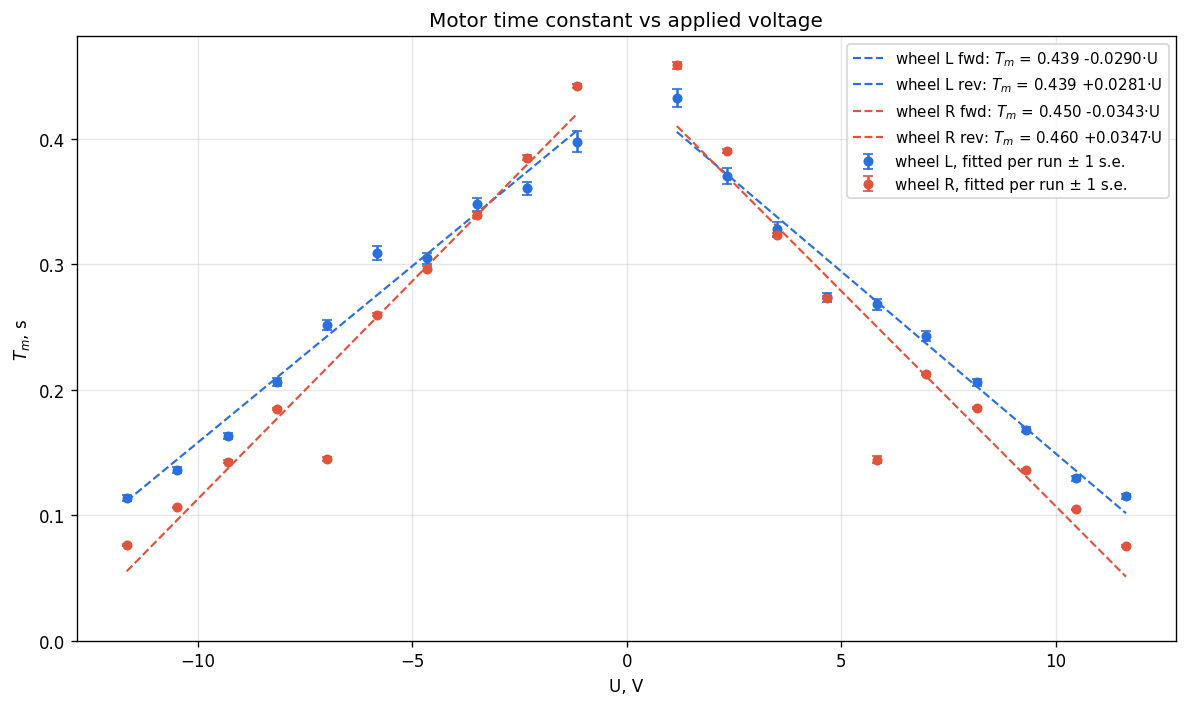

In [34]:
colors = {'L': '#2a6fdb', 'R': '#e0533d'}

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
     plt.errorbar(U, T_m_run[wh], yerr=T_m_err[wh], fmt='o', color=colors[wh], ms=5,
                 capsize=3, label=f'wheel {wh}, fitted per run ± 1 s.e.')
     for side, name in ((U > 0, 'fwd'), (U < 0, 'rev')):
        m = side & ~np.isnan(T_m_run[wh])                            # runs of this direction where the wheel moved
        b, a = np.polyfit(U[m], T_m_run[wh][m], 1)                   # least squares for T_m = a + b * U
        u = np.array([U[m].min(), U[m].max()])
        plt.plot(u, a + b * u, '--', color=colors[wh], lw=1.3,
                 label=f'wheel {wh} {name}: $T_m$ = {a:.3f} {b:+.4f}·U')
        print(f'{wh} {name}: T_m = {a:.3f} {b:+.4f} * U  (s, U in V)')
plt.xlabel('U, V'); plt.ylabel('$T_m$, s')
plt.title('Motor time constant vs applied voltage')
plt.ylim(bottom=0)
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/T_m.png')

wheel L fwd: slope=0.1196, intercept=3.3617, k_e=0.9740 V*s/rad
wheel L rev: slope=0.1044, intercept=-3.8591, k_e=1.1152 V*s/rad
wheel R fwd: slope=0.1025, intercept=5.2990, k_e=1.1365 V*s/rad
wheel R rev: slope=0.0965, intercept=-5.5387, k_e=1.2072 V*s/rad


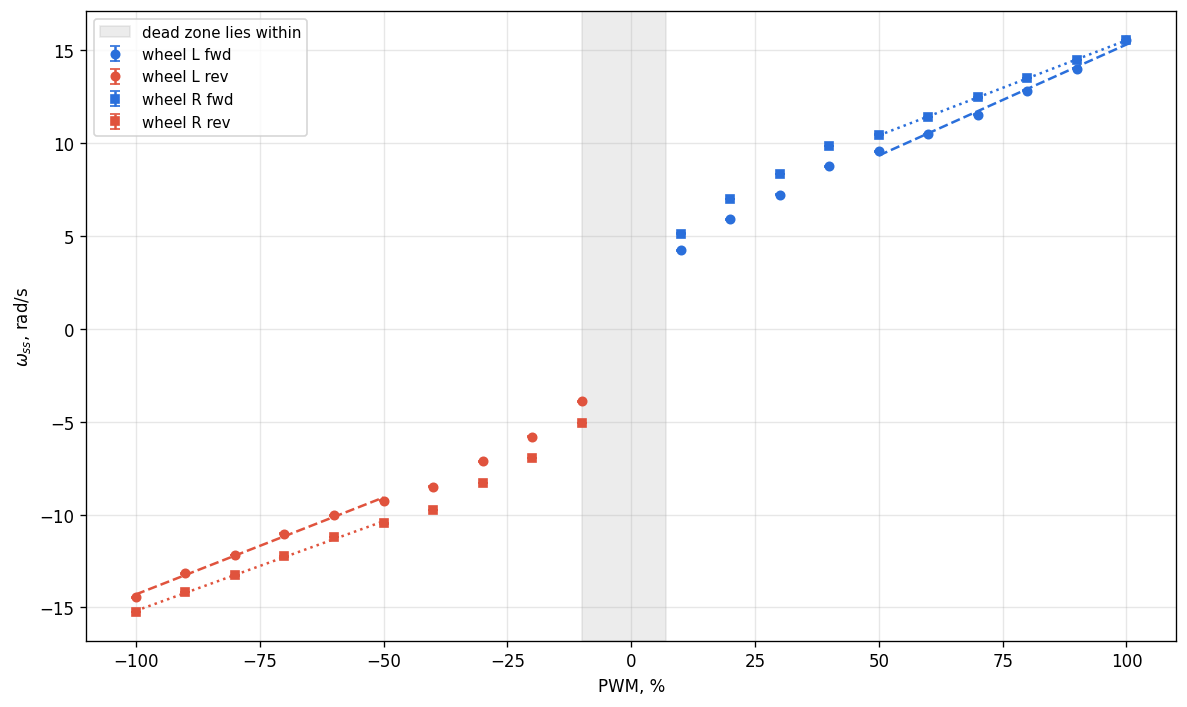

In [35]:
markers = {'L': 'o', 'R': 's'}                                       # marker per wheel
styles = {'L': '--', 'R': ':'}                                       # fit line style per wheel
dir_colors = {'fwd': '#2a6fdb', 'rev': '#e0533d'}                    # colour per direction
lin = np.abs(pct) >= 50                                              # your choice: the linear part, as a mask on pct

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    for side, name in ((pct > 0, 'fwd'), (pct < 0, 'rev')):
        m = side & ~np.isnan(w_ss[wh])                               # levels of this direction where the wheel moved
        plt.errorbar(pct[m], w_ss[wh][m], yerr=w_err[wh][m], fmt=markers[wh], color=dir_colors[name],
                     ms=5, capsize=3, label=f'wheel {wh} {name}')
        f = m & lin                                                  # points used for the line
        slope, icpt = np.polyfit(pct[f], w_ss[wh][f], 1)             # least squares for w = slope * PWM + icpt

        # Plot the line over the chosen range (linear region)
        x_line = pct[f]
        plt.plot(x_line, slope * x_line + icpt, linestyle=styles[wh], color=dir_colors[name], lw=1.5)

        # Calculate k_e = U_bat / (100 * slope)
        u_bat = bat_all.mean()
        k_e_calc = u_bat / (100 * slope)
        print(f'wheel {wh} {name}: slope={slope:.4f}, intercept={icpt:.4f}, k_e={k_e_calc:.4f} V*s/rad')

plt.axvspan(-10, 7, color='grey', alpha=0.15, label='dead zone lies within')
plt.xlabel('PWM, %'); plt.ylabel('$\\omega_{ss}$, rad/s')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/speed_pwm.png')

Step response for the report: both wheels at full power, simulated with `odeint` using each wheel's identified $k_e$ and $T_m$ from above.

L: max |error| 1.59 rad, error at the end -1.58 rad (-5.3 %)
R: max |error| 1.10 rad, error at the end -1.10 rad (-3.6 %)


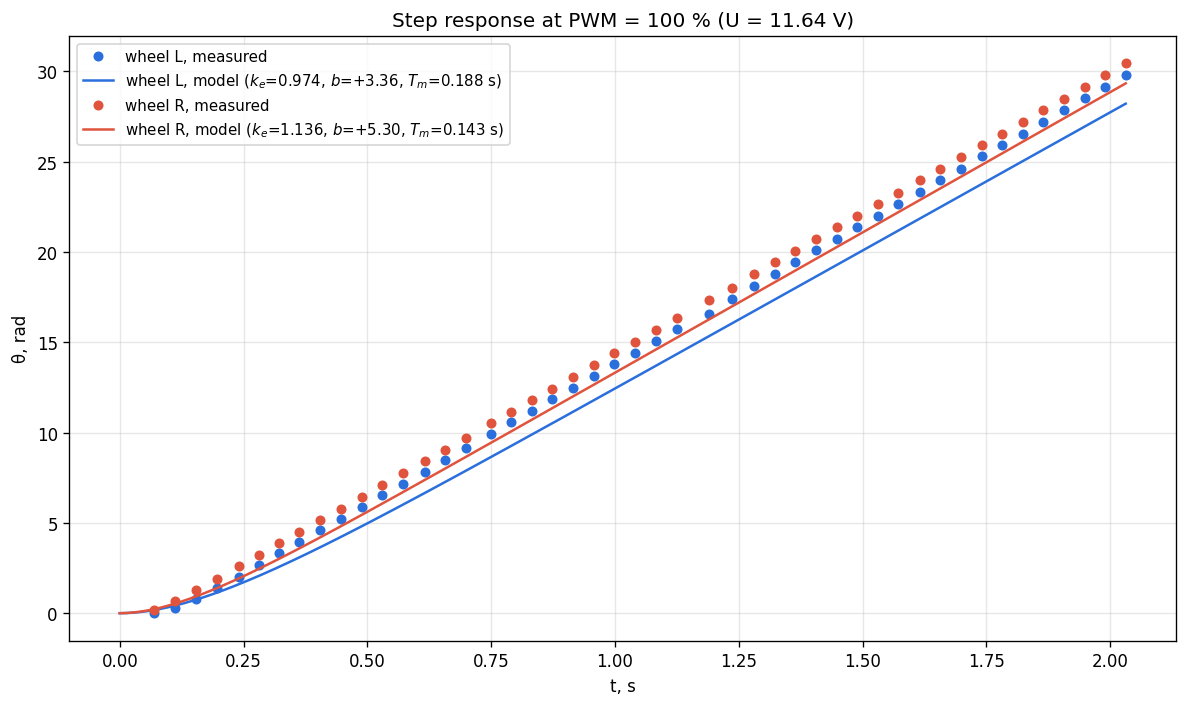

In [36]:
def motor_model(state, t, u, T_m, k_e, b):
    speed, angle = state                                             # motor state space
    w_target = u / k_e + b                                           # steady-state speed from the fitted line, rad/s
    return [(w_target - speed) / T_m, speed]

run = next(r for r in runs if r['power'] == 100)                     # full-power run
t_sim = np.linspace(0, run['time'][-1], 300)                         # fine time grid for the simulation
colors = {'L': '#2a6fdb', 'R': '#e0533d'}

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    p = params[wh, 'fwd']                                            # +100 % uses the forward line
    sim = odeint(motor_model, [0, 0], t_sim, args=(run['U'], p['T_m'], p['k_e'], p['b']))[:, 1]  # simulated angle
    plt.plot(run['time'], run[wh], 'o', color=colors[wh], ms=5, label=f'wheel {wh}, measured')
    plt.plot(t_sim, sim, '-', color=colors[wh], lw=1.5,
             label=f'wheel {wh}, model ($k_e$={p["k_e"]:.3f}, $b$={p["b"]:+.2f}, $T_m$={p["T_m"]:.3f} s)')
    err = np.interp(run['time'], t_sim, sim) - run[wh]               # model minus measurement, rad
    print(f'{wh}: max |error| {np.max(np.abs(err)):.2f} rad, error at the end {err[-1]:+.2f} rad '
          f'({100 * err[-1] / run[wh][-1]:+.1f} %)')
plt.xlabel('t, s'); plt.ylabel('θ, rad')
plt.title(f'Step response at PWM = 100 % (U = {run["U"]:.2f} V)')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/step_response.png')

How much the wheels differ at the same command, and what that does to a differential-drive robot (wheel radius and track width from the Week 4 odometry code). Also: how far the fitted line is off at low PWM.

In [37]:
r_wheel, W = 0.043, 0.194                                           # wheel radius and track width, m
for p in (100, 50, -50, -100):
    i = list(pct).index(p)
    wL, wR = w_ss['L'][i], w_ss['R'][i]
    diff = 100 * (wL - wR) / ((wL + wR) / 2)                         # left vs right, %
    yaw = np.degrees(r_wheel * (wR - wL) / W)                        # deg/s, positive = turning left
    v = r_wheel * (wL + wR) / 2                                      # m/s
    print(f'PWM {p:4d}: wL={wL:6.2f} wR={wR:6.2f} diff={diff:+5.1f} %  yaw rate={yaw:+5.1f} deg/s  v={v:.3f} m/s')

print('fitted line at low PWM (L), error in %:')
for p in (-30, -20, -10, 10, 20, 30):
    i = list(pct).index(p)
    q = params['L', 'fwd' if p > 0 else 'rev']
    w_line = q['slope'] * p + q['b']                                 # what the fitted line predicts
    print(f'  PWM {p:4d}: {100 * (w_ss["L"][i] - w_line) / w_ss["L"][i]:.0f} %')

PWM  100: wL= 15.55 wR= 15.57 diff= -0.1 %  yaw rate= +0.2 deg/s  v=0.669 m/s
PWM   50: wL=  9.56 wR= 10.46 diff= -8.9 %  yaw rate=+11.3 deg/s  v=0.430 m/s
PWM  -50: wL= -9.25 wR=-10.48 diff=-12.4 %  yaw rate=-15.5 deg/s  v=-0.424 m/s
PWM -100: wL=-14.47 wR=-15.24 diff= -5.2 %  yaw rate= -9.8 deg/s  v=-0.639 m/s
fitted line at low PWM (L), error in %:
  PWM  -30: 2 %
  PWM  -20: -2 %
  PWM  -10: -26 %
  PWM   10: -8 %
  PWM   20: 2 %
  PWM   30: 4 %


## Chirp simulation
The identified model is simulated with the logged PWM, held constant between samples, for both wheels. *With dead zone:* ω = 0 for |PWM| < 10 %, the fitted line above it. *Without dead zone:* the fitted line all the way down to PWM = 0. Only the dead zone changes between the two.


wheel L, without dead zone: RMSE 2.13 rad, fit 18.1 %
wheel L, with dead zone: RMSE 1.05 rad, fit 59.6 %
wheel R, without dead zone: RMSE 6.97 rad, fit -127.3 %
wheel R, with dead zone: RMSE 3.29 rad, fit -7.3 %


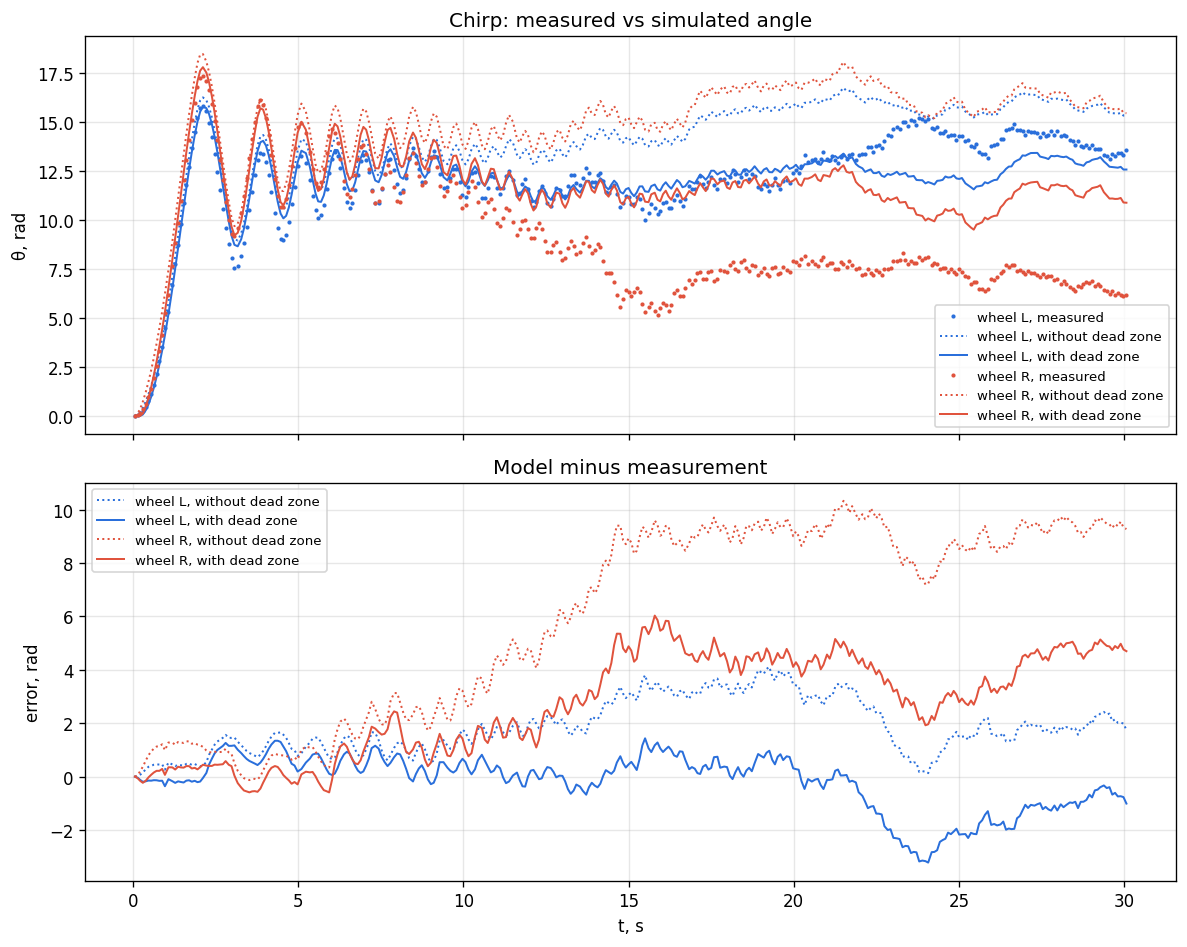

In [38]:
sig = np.loadtxt('signal_data.txt')                                  # columns: phase, PWM, encL, encR, time_ms, battery
sig = sig[sig[:, 0] == 3]                                            # chirp lines only (phase 2 = zero block)
t_c = sig[:, 4] / 1000                                               # time, s
pwm_c = sig[:, 1]                                                    # PWM actually sent, %
U_c = pwm_c / 100 * sig[:, 5]                                        # applied voltage, V
meas = {'L': np.deg2rad(sig[:, 2]), 'R': np.deg2rad(sig[:, 3])}      # measured angle, rad

def simulate(wh, dead_zone):

    theta, w = np.zeros(len(t_c)), 0.0                               # angle, rad; speed, rad/s
    for k in range(len(t_c) - 1):
        p = params[wh, 'fwd' if pwm_c[k] > 0 else 'rev']
        if pwm_c[k] == 0 or (dead_zone and abs(pwm_c[k]) < p['dz']):
            w_target = 0.0                                           # wheel held by the dead zone
        else:
            w_target = U_c[k] / p['k_e'] + p['b']                     # the fitted line
        dt = t_c[k + 1] - t_c[k]
        e = np.exp(-dt / p['T_m'])
        theta[k + 1] = theta[k] + w_target * dt + (w - w_target) * p['T_m'] * (1 - e)
        w = w_target + (w - w_target) * e
    return theta

def fit_percent(y, y_sim):
    return 100 * (1 - np.linalg.norm(y - y_sim) / np.linalg.norm(y - y.mean()))  # 100 % = perfect fit

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), dpi=120, sharex=True)
for wh in ('L', 'R'):
    ax1.plot(t_c, meas[wh], '.', color=colors[wh], ms=3, label=f'wheel {wh}, measured')
    for dz, ls in ((False, ':'), (True, '-')):
        sim = simulate(wh, dz)
        err = sim - meas[wh]                                         # model minus measurement, rad
        name = f'wheel {wh}, {"with" if dz else "without"} dead zone'
        print(f'{name}: RMSE {np.sqrt(np.mean(err ** 2)):.2f} rad, fit {fit_percent(meas[wh], sim):.1f} %')
        ax1.plot(t_c, sim, ls, color=colors[wh], lw=1.2, label=name)
        ax2.plot(t_c, err, ls, color=colors[wh], lw=1.2, label=name)
ax1.set_ylabel('θ, rad'); ax1.set_title('Chirp: measured vs simulated angle')
ax2.set_ylabel('error, rad'); ax2.set_xlabel('t, s'); ax2.set_title('Model minus measurement')
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/chirp_sim.png')

## Chirp: amplitude ratio vs frequency
For each sample, the speed and voltage amplitudes are taken over one period of the chirp around it, at the instantaneous frequency $f(t) = f_0 + (f_1 - f_0)\,t/T$. The ratio is compared with the first-order model $1/(k_e\sqrt{1 + (2\pi f T_m)^2})$.


L: measured ratio 1.24 (f < 1 Hz, median), 1/k_e = 0.96, 1/k_e + b/A_U = 1.35 rad/s per V
R: measured ratio 1.35 (f < 1 Hz, median), 1/k_e = 0.85, 1/k_e + b/A_U = 1.44 rad/s per V


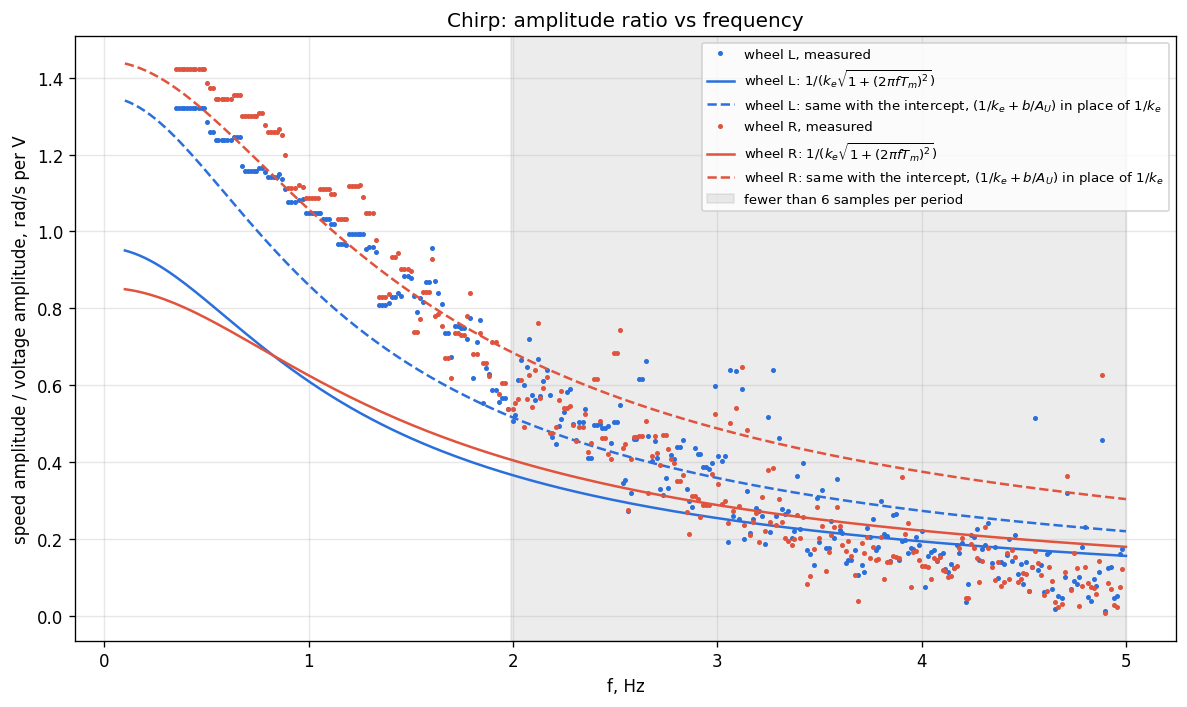

In [39]:
f0, f1, T_chirp = 0.1, 5, 30                                         # chirp settings in motor_signal.qrs
f_c = f0 + (f1 - f0) * t_c / T_chirp                                 # instantaneous frequency, Hz
A_U = np.abs(U_c).max()                                              # input amplitude, V
f_line = np.linspace(f0, f1, 200)

plt.figure(figsize=(10, 6), dpi=120)
for wh in ('L', 'R'):
    w_meas = np.gradient(meas[wh], t_c)                              # measured speed, rad/s
    ratio = np.full(len(t_c), np.nan)
    for k in range(len(t_c)):
        half = 0.5 / f_c[k]                                          # half a period at this frequency, s
        if t_c[k] - half >= t_c[0] and t_c[k] + half <= t_c[-1]:     # a full period fits in the record
            win = np.abs(t_c - t_c[k]) <= half
            ratio[k] = np.ptp(w_meas[win]) / np.ptp(U_c[win])        # speed amplitude / voltage amplitude
    plt.plot(f_c, ratio, '.', color=colors[wh], ms=4, label=f'wheel {wh}, measured')
    k_e = np.mean([params[wh, d]['k_e'] for d in ('fwd', 'rev')])    # averaged over the two directions
    T_m = np.mean([params[wh, d]['T_m'] for d in ('fwd', 'rev')])
    b = np.mean([abs(params[wh, d]['b']) for d in ('fwd', 'rev')])
    lag = np.sqrt(1 + (2 * np.pi * f_line * T_m) ** 2)
    plt.plot(f_line, 1 / (k_e * lag), '-', color=colors[wh], label=f'wheel {wh}: $1/(k_e\\sqrt{{1 + (2\\pi f T_m)^2}})$')
    plt.plot(f_line, (1 / k_e + b / A_U) / lag, '--', color=colors[wh], label=f'wheel {wh}: same with the intercept, $(1/k_e + b/A_U)$ in place of $1/k_e$')
    print(f'{wh}: measured ratio {np.nanmedian(ratio[f_c < 1]):.2f} (f < 1 Hz, median), '
          f'1/k_e = {1 / k_e:.2f}, 1/k_e + b/A_U = {1 / k_e + b / A_U:.2f} rad/s per V')
fs = 1 / np.median(np.diff(t_c))                                     # sampling rate, Hz
plt.axvspan(fs / 6, f1, color='grey', alpha=0.15, label='fewer than 6 samples per period')
plt.xlabel('f, Hz'); plt.ylabel('speed amplitude / voltage amplitude, rad/s per V')
plt.title('Chirp: amplitude ratio vs frequency')
plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/chirp_ratio.png')

## Artifacts
Zero drift: the 0 % level of both step runs, logged with the motors off. Logging interval: time between consecutive log lines, against the 5 ms target.


run1, 0 % level: 46 samples over 1.9 s, max |θ|: L 0°, R 0°
run2, 0 % level: 37 samples over 1.9 s, max |θ|: L 0°, R 0°
steps, run 1: Δt median 42 ms, 95th percentile 51 ms, max 72 ms
steps, run 2: Δt median 52 ms, 95th percentile 65 ms, max 93 ms
chirp: Δt median 84 ms, 95th percentile 111 ms, max 135 ms


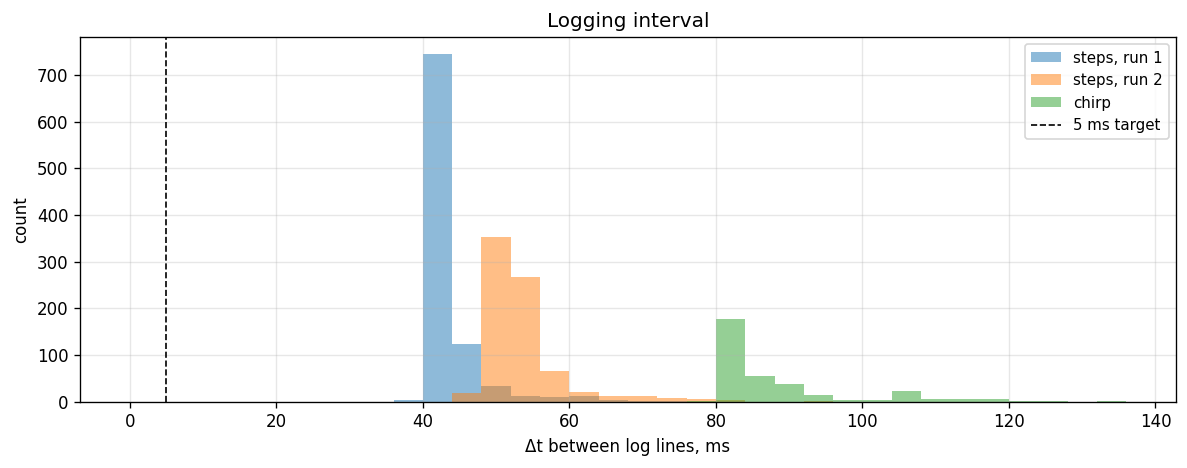

In [40]:
# zero drift: the 0 % level, logged with the motors off
for name in ('run1', 'run2'):
    r0 = next(r for r in all_runs[name] if r['power'] == 0)
    print(f'{name}, 0 % level: {len(r0["time"])} samples over {r0["time"][-1] - r0["time"][0]:.1f} s, '
          f'max |θ|: L {np.degrees(np.abs(r0["L"]).max()):.0f}°, R {np.degrees(np.abs(r0["R"]).max()):.0f}°')

# logging interval jitter: time between consecutive log lines
dts = {'steps, run 1': np.concatenate([np.diff(r['time']) for r in all_runs['run1']]),
       'steps, run 2': np.concatenate([np.diff(r['time']) for r in all_runs['run2']]),
       'chirp':        np.diff(t_c)}
plt.figure(figsize=(10, 4), dpi=120)
for name, dt in dts.items():
    dt_ms = 1000 * dt                                                # ms
    print(f'{name}: Δt median {np.median(dt_ms):.0f} ms, 95th percentile {np.percentile(dt_ms, 95):.0f} ms, '
          f'max {dt_ms.max():.0f} ms')
    plt.hist(dt_ms, bins=np.arange(0, 140, 4), alpha=0.5, label=name)
plt.axvline(5, color='k', ls='--', lw=1, label='5 ms target')
plt.xlabel('Δt between log lines, ms'); plt.ylabel('count'); plt.title('Logging interval')
plt.grid(alpha=0.3); plt.legend(fontsize=9)
plt.tight_layout(); plt.savefig('report_figs/dt_jitter.png')

## Repeatability and load
Run 1 vs. run 2 (both lifted), compared per volt because the battery was ≈ 0.35 V lower in run 2. Lifted (run 2) vs. on the floor at ±50 %, at nearly the same battery voltage.


wheel L: speed per volt, run 2 vs run 1: -3.6 % (mean over |PWM| ≥ 50 %); T_m mean: run 1 0.192 s, run 2 0.198 s
wheel R: speed per volt, run 2 vs run 1: -1.6 % (mean over |PWM| ≥ 50 %); T_m mean: run 1 0.148 s, run 2 0.155 s
lifted (run 2) → floor:
  PWM  -50, wheel L: ω_ss  -8.56 →  -6.82 rad/s (-20.3 %), T_m 0.273 → 0.393 s
  PWM  -50, wheel R: ω_ss  -9.92 →  -7.32 rad/s (-26.2 %), T_m 0.251 → 0.389 s
  PWM  +50, wheel L: ω_ss   8.67 →   7.33 rad/s (-15.5 %), T_m 0.261 → 0.483 s
  PWM  +50, wheel R: ω_ss   9.96 →   7.51 rad/s (-24.6 %), T_m 0.240 → 0.364 s


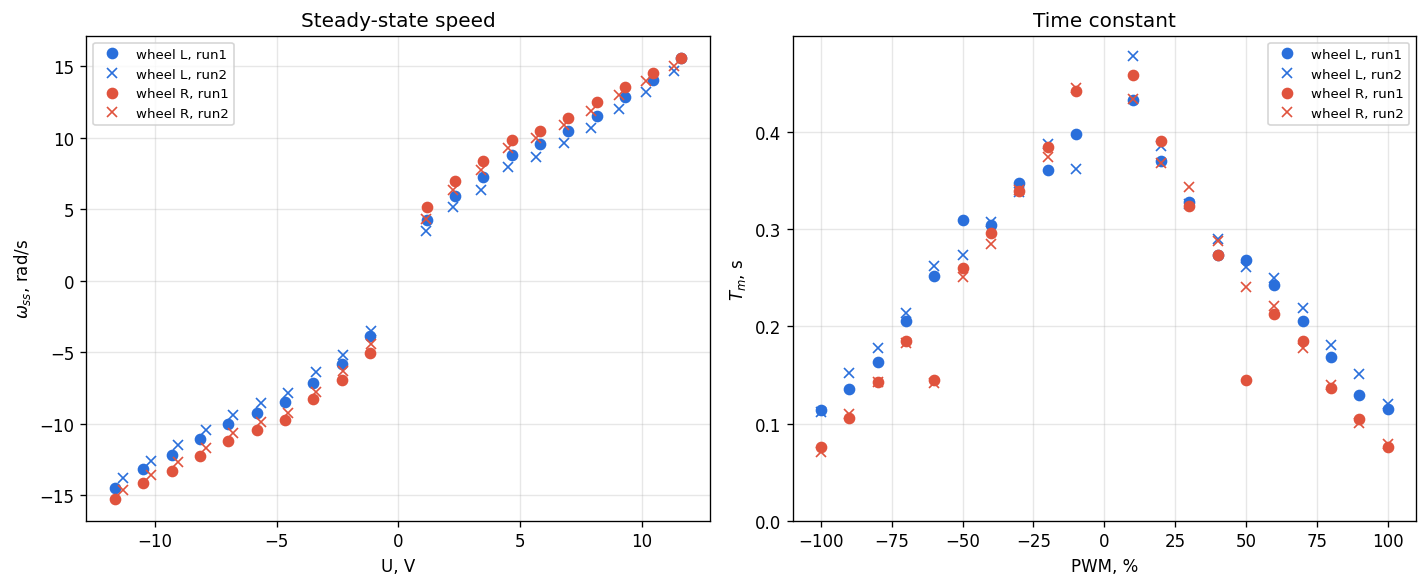

In [41]:
def fit_all(runs):
    res = {wh: np.full((len(runs), 2), np.nan) for wh in ('L', 'R')}  # per level: w_ss (rad/s), T_m (s)
    for wh in ('L', 'R'):
        for i, r in enumerate(runs):
            if abs(r[wh][-1]) >= 1:                                  # the wheel moved
                res[wh][i] = fit_run(r['time'], r[wh])[0]
    return res

fits = {name: fit_all(rs) for name, rs in all_runs.items()}
lv = {name: {'pct': np.array([r['power'] for r in rs]),             # PWM of every level, %
             'U':   np.array([r['U'] for r in rs])}                  # voltage of every level, V
      for name, rs in all_runs.items()}
assert np.array_equal(lv['run1']['pct'], lv['run2']['pct'])         # same levels in the same order

# repeatability: run 1 vs run 2, both lifted; compared per volt because the battery differs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=120)
hi = np.abs(lv['run1']['pct']) >= 50                                 # the linear part
for wh in ('L', 'R'):
    for name, mk in (('run1', 'o'), ('run2', 'x')):
        ax1.plot(lv[name]['U'], fits[name][wh][:, 0], mk, color=colors[wh], label=f'wheel {wh}, {name}')
        ax2.plot(lv[name]['pct'], fits[name][wh][:, 1], mk, color=colors[wh], label=f'wheel {wh}, {name}')
    g1 = fits['run1'][wh][hi, 0] / lv['run1']['U'][hi]               # speed per volt, run 1
    g2 = fits['run2'][wh][hi, 0] / lv['run2']['U'][hi]               # speed per volt, run 2
    print(f'wheel {wh}: speed per volt, run 2 vs run 1: {100 * np.mean(g2 / g1 - 1):+.1f} % (mean over |PWM| ≥ 50 %); '
          f'T_m mean: run 1 {np.mean(fits["run1"][wh][hi, 1]):.3f} s, run 2 {np.mean(fits["run2"][wh][hi, 1]):.3f} s')
ax1.set_xlabel('U, V'); ax1.set_ylabel('$\\omega_{ss}$, rad/s'); ax1.set_title('Steady-state speed')
ax2.set_xlabel('PWM, %'); ax2.set_ylabel('$T_m$, s'); ax2.set_title('Time constant'); ax2.set_ylim(bottom=0)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('report_figs/repeatability.png')

# load: lifted (run 2) vs on the floor, at nearly the same battery voltage
print('lifted (run 2) → floor:')
for p in (-50, 50):
    i2, i_f = list(lv['run2']['pct']).index(p), list(lv['floor']['pct']).index(p)
    for wh in ('L', 'R'):
        (w2, T2), (wf, Tf) = fits['run2'][wh][i2], fits['floor'][wh][i_f]
        print(f'  PWM {p:+4d}, wheel {wh}: ω_ss {w2:6.2f} → {wf:6.2f} rad/s ({100 * (wf / w2 - 1):+.1f} %), '
              f'T_m {T2:.3f} → {Tf:.3f} s')


## Analysis

### 1. Model quality

1. The step result is good at ~5% error. The simulated angle at the end of the +100% step is off by −5.3% (L) and −3.6% (R).
2. On the chirp, the left wheel performed moderately(60% while the target being 85%) but the right wheel performed worse than the flat line(-7%, a fit below 0%).
3. A small speed error that hardly shows in a 2 s step builds up in the angle over the 30 s chirp: R ends at 6.2 rad measured vs 10.8 rad simulated.

### 2. Forward vs. backward

Forward direction is faster on both motors by 14% L and 6% R, derived from k_e. T_m doesnot differ meaningfully between directions(L 0.188 s forward vs.
0.197 s backward, R 0.143 vs. 0.152, respectively). The standard deviation across levels is about ±0.06 s, so the difference of 0.009s is lost in the
spread. One of the physical causes of the speed difference is possibly that the friction in the gearbox depends on the direction of rotation or the motor driver; it was not tested.


### 3. Artifacts that matter for odometry and

1. Zero drift: the 0% level stayed at 0 degrees on both wheels so the ecnoders are reliable ar rest.
2. The logging interval: 42 / 52 / 84 ms median (target 5 ms), max 72 / 93 / 135 ms
3. Left/Right asymmetry: Left wheel is slower than Right one, −8.9% at +50%, −12.4% at −50% (yaw +11.3 / −15.5 deg/s)
4. Dead zone: below 10% PWM the wheels dont move.
5. Motor start order: The right motor starts ~20ms before the left one.
6. Load: On the floor, w_ss is 15-26% lower than when lifted.

Zero drift and the logging interval matter for the odometry, since they are crucial for estimating the position. The zero drift is none, so it is good but, the logging interval is higher than the expected one, between two samples the robot moves along an arc, because the heading is changing the whole time.
### 4. What the chirp showed.

I chose chirp. Since it crosses zero 150 times, each time it passes through 0, the real wheel stops for a bit. The model without a dead zone keeps moving, so the model piles up angle that the real wheel never makes, once at every crossing. That's why adding the dead zone helps so much on the chirp.
